In [ ]:
# --------------------------
# IMPORTS
# --------------------------

import pandas as pd
import numpy as np
import re
import string
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import MiniBatchKMeans
from scipy.sparse import hstack, csr_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
# --------------------------
# LOAD DATA
# --------------------------
diet = pd.read_csv('/kaggle/input/foodcom-recipes-and-reviews/recipes.csv')

selected_columns = ['Name','Calories', 'FatContent', 'SaturatedFatContent',
                    'CholesterolContent', 'SodiumContent', 'CarbohydrateContent',
                    'FiberContent', 'SugarContent', 'ProteinContent','RecipeInstructions']

diet = diet[selected_columns]

In [4]:
# --------------------------
# TEXT CLEANING
# --------------------------
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[@#$%^&*!`~]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def clean_instructions(text):
    if pd.isna(text):
        return ""
    text = text.lstrip('c("').rstrip('",)')
    text = text.replace(',', '')
    text = text.translate(str.maketrans("", "", string.punctuation))
    return text

diet['Name'] = diet['Name'].apply(preprocess_text)
diet['RecipeInstructions'] = diet['RecipeInstructions'].apply(clean_instructions)

In [5]:
# --------------------------
# USER PROFILE
# --------------------------
user_profile = {
    "age": 25,
    "sex": "female",
    "weight": 60,       # kg
    "height": 165,      # cm
    "activity_level": "moderate", # sedentary, lightly_active, moderate, very_active, extra_active
    "goal": "weight_loss",       # weight_loss, weight_gain, maintenance
    "diet_preference": "vegetarian",
    "allergies": ["nuts"]
}


In [6]:
# --------------------------
# BMR, TDEE, MACROS
# --------------------------
def calculate_bmr(weight, height, age, sex):
    if sex == "male":
        return 9.99*weight + 6.25*height - 4.92*age + 5
    else:
        return 9.99*weight + 6.25*height - 4.92*age - 161

def calculate_tdee(bmr, activity_level):
    multipliers = {
        "sedentary": 1.2,
        "lightly_active": 1.375,
        "moderate": 1.55,
        "very_active": 1.725,
        "extra_active": 1.9
    }
    return bmr * multipliers.get(activity_level, 1.2)

def adjust_calories(tdee, goal):
    if goal == "weight_loss":
        return tdee - 500
    elif goal == "weight_gain":
        return tdee + 500
    return tdee

def calculate_macros(calories, goal):
    if goal == "weight_loss":
        protein_ratio, fat_ratio, carb_ratio = 0.3, 0.3, 0.4
    elif goal == "weight_gain":
        protein_ratio, fat_ratio, carb_ratio = 0.25, 0.3, 0.45
    else:
        protein_ratio, fat_ratio, carb_ratio = 0.3, 0.3, 0.4
    
    protein = (calories * protein_ratio) / 4
    fat = (calories * fat_ratio) / 9
    carbs = (calories * carb_ratio) / 4
    return protein, fat, carbs

bmr = calculate_bmr(user_profile["weight"], user_profile["height"], user_profile["age"], user_profile["sex"])
tdee = calculate_tdee(bmr, user_profile["activity_level"])
target_calories = adjust_calories(tdee, user_profile["goal"])
target_protein, target_fat, target_carbs = calculate_macros(target_calories, user_profile["goal"])

print(f"BMR: {bmr:.2f}, TDEE: {tdee:.2f}")
print(f"Target Calories: {target_calories:.2f}")
print(f"Target Protein: {target_protein:.2f}, Fat: {target_fat:.2f}, Carbs: {target_carbs:.2f}")

BMR: 1346.65, TDEE: 2087.31
Target Calories: 1587.31
Target Protein: 119.05, Fat: 52.91, Carbs: 158.73


In [7]:
def weight_status(weight, height):
    height_m = height / 100
    bmi = weight / (height_m ** 2)
    if bmi < 18.5:
        status = "Underweight"
    elif 18.5 <= bmi < 25:
        status = "Normal weight"
    elif 25 <= bmi < 30:
        status = "Overweight"
    else:
        status = "Obese"
    return bmi, status

bmi, status = weight_status(user_profile["weight"], user_profile["height"])
print(f"BMI: {bmi:.2f}, Status: {status}")

BMI: 22.04, Status: Normal weight


In [8]:
# --------------------------
# FILTER RECIPES (Diet + Allergies)
# --------------------------
filtered_diet = diet.copy()

# Diet preference filter
if user_profile["diet_preference"] in ["vegetarian", "vegan"]:
    filtered_diet = filtered_diet[filtered_diet["RecipeInstructions"].str.contains(user_profile["diet_preference"], case=False, na=False)]

# Allergies filter
for allergen in user_profile["allergies"]:
    filtered_diet = filtered_diet[~filtered_diet["RecipeInstructions"].str.contains(allergen, case=False, na=False)]

print(f"Filtered recipes: {filtered_diet.shape[0]}")
filtered_diet.head()


Filtered recipes: 716


,Name,Calories,FatContent,SaturatedFatContent,CholesterolContent,SodiumContent,CarbohydrateContent,FiberContent,SugarContent,ProteinContent,RecipeInstructions
1901,swiss chard dolmades,478.1,23.4,9.5,56.1,2234.5,51.7,6.0,6.9,18.0,Saute riceorzo and garlic in butter for 1 mi...
1971,polenta pizzarina,1057.7,10.9,1.6,0.0,182.8,220.7,28.5,22.0,35.0,Preheat oven to 350F Put water in a large pot ...
2463,linguini with seafood - buon'appetito,574.1,10.3,1.6,142.5,985.8,71.6,4.2,5.8,43.2,Serve pasta and sauce in a large bowl on the t...
3178,millet loaf,149.8,2.8,0.4,0.0,142.6,27.3,3.8,1.8,4.1,Rinse millet and put it in a medium saucepan w...
5583,belly buster,562.4,19.1,10.6,67.8,382.6,67.5,4.4,6.2,29.4,This recipe can be made vegetarian leave out t...


In [9]:
# --------------------------
# TEXT EMBEDDINGS + SCALING NUTRITION
# --------------------------
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
recipe_text_features = vectorizer.fit_transform(filtered_diet['RecipeInstructions'])

nutritional_cols = ['Calories', 'ProteinContent', 'FatContent', 'CarbohydrateContent']
scaler = StandardScaler()
nutrition_features = scaler.fit_transform(filtered_diet[nutritional_cols])

recipe_features = hstack([nutrition_features, recipe_text_features])

print("Feature matrix shape:", recipe_features.shape)



Feature matrix shape: (716, 4768)


In [10]:
# Optional: Clustering for diversity
kmeans = MiniBatchKMeans(n_clusters=20, random_state=42, n_init=10)
filtered_diet['Cluster'] = kmeans.fit_predict(recipe_features)

print("Clustering done. Sample clusters:")
print(filtered_diet[['Name', 'Cluster']].head())


Clustering done. Sample clusters:
                                       Name  Cluster
1901                   swiss chard dolmades       16
1971                      polenta pizzarina       17
2463  linguini with seafood - buon'appetito        3
3178                            millet loaf        8
5583                           belly buster       16


In [11]:
# --------------------------
# CONTENT-BASED RECOMMENDATION
# --------------------------
# Create user vector with exact column names
user_input_df = pd.DataFrame([[target_calories, target_protein, target_fat, target_carbs]],
                             columns=['Calories', 'ProteinContent', 'FatContent', 'CarbohydrateContent'])

# Scale numeric features
user_vector = scaler.transform(user_input_df)

# Combine with text features (all zeros for user)
user_vector_sparse = hstack([user_vector, csr_matrix((1, recipe_text_features.shape[1]))])

# Compute cosine similarities
similarities = cosine_similarity(user_vector_sparse, recipe_features)

# Assign similarity scores
filtered_diet['Similarity'] = similarities[0]

# Get top 5 recipes
top_5 = filtered_diet.sort_values('Similarity', ascending=False).head(5)
print("Top 5 recommended recipes:")
print(top_5[['Name', 'Calories', 'ProteinContent', 'FatContent', 'CarbohydrateContent', 'Similarity']])

Top 5 recommended recipes:
                                                     Name  Calories  \
224425                        yummy vegetarian meat sauce    1160.0   
79151                        the best deep dish pizza pie    6378.6   
429464                                 southwestern chili     718.0   
343061                         delicious vegetarian chili     964.1   
24961   easy white sauce (with variations) for the mic...    1552.6   

        ProteinContent  FatContent  CarbohydrateContent  Similarity  
224425            74.9        24.6                169.6    0.944023  
79151            311.6       362.8                470.1    0.930273  
429464            62.0        21.3                 74.8    0.929244  
343061            62.0        19.8                149.3    0.921850  
24961             89.4        99.5                105.4    0.920200  


In [12]:

# --------------------------
# 7-DAY MEAL PLAN GENERATOR
# --------------------------
def generate_7day_plan(filtered_diet, target_calories_per_day):
    days = []
    for day in range(7):
        day_plan = []
        remaining_calories = target_calories_per_day
        # Shuffle recipes for variety
        recipes_shuffled = filtered_diet.sample(frac=1, random_state=day)
        for _, recipe in recipes_shuffled.iterrows():
            if recipe['Calories'] <= remaining_calories:
                day_plan.append(recipe)
                remaining_calories -= recipe['Calories']
            if remaining_calories <= 50:  # small threshold
                break
        days.append(day_plan)
    return days

meal_plan_7days = generate_7day_plan(filtered_diet, target_calories)
print("7-day meal plan generated!")

7-day meal plan generated!


In [13]:
# --------------------------
# DISPLAY MEAL PLAN 
# --------------------------
for i, day in enumerate(meal_plan_7days, 1):
    print(f"\n{'='*40}")
    print(f"🍽️  DAY {i} MEAL PLAN")
    print(f"{'='*40}")

    # Compute totals
    total_calories = sum([r['Calories'] for r in day])
    total_protein = sum([r['ProteinContent'] for r in day])
    total_fat = sum([r['FatContent'] for r in day])
    total_carbs = sum([r['CarbohydrateContent'] for r in day])

    print(f"🔹 Total Calories: {total_calories:.0f} kcal")
    print(f"🔹 Protein: {total_protein:.1f} g | Fat: {total_fat:.1f} g | Carbs: {total_carbs:.1f} g")
    print(f"{'-'*40}\n")

    # Print each meal
    for j, meal in enumerate(day, 1):
        print(f"🥗 Meal {j}: {meal['Name'].title()} ({meal['Calories']:.0f} kcal)")
        print(f"   💪 Protein: {meal['ProteinContent']:.1f} g | 🥑 Fat: {meal['FatContent']:.1f} g | 🍞 Carbs: {meal['CarbohydrateContent']:.1f} g")
        print(f"   📖 Instructions: {meal['RecipeInstructions']}")
        print(f"{'-'*40}")



🍽️  DAY 1 MEAL PLAN
🔹 Total Calories: 1542 kcal
🔹 Protein: 64.0 g | Fat: 40.8 g | Carbs: 246.3 g
----------------------------------------

🥗 Meal 1: Fiesta Mix (199 kcal)
   💪 Protein: 5.4 g | 🥑 Fat: 1.5 g | 🍞 Carbs: 44.5 g
   📖 Instructions: Cook brown rice according to package directions 30 minutes Add remaining ingredients in a large saucepan and cook on medium heat until warmed through Eat wrapped in a burrito shell as a dip for tortilla chips or by itself  Good cold or hot For Vegetarian option Use the vegetarian Worcestershire Sauce
----------------------------------------
🥗 Meal 2: Kale-Corn Fritters (315 kcal)
   💪 Protein: 11.0 g | 🥑 Fat: 10.2 g | 🍞 Carbs: 47.4 g
   📖 Instructions: In a large bowl stir together the flour cornmeal salt kale and corn In a medium bowl lightly beat the eggs Mix in the oilbutter and milk Make a well in the center of the dry ingredients and pour in the wet ingredients This makes mixing in easier and faster If you are using the onion sautee it then 

In [14]:
# 4. Hybrid Recommendation System Architecture

## 4.1 Hybrid Architecture Overview

# Our hybrid recommendation system consists of three primary components:
# 1. **Neural Collaborative Filtering Module** - learns user and recipe embeddings from interaction patterns
# 2. **Content-Based Deep Learning Module** - processes recipe features through deep autoencoder
# 3. **Ensemble Layer** - intelligently combines predictions using learned weighting mechanism


In [15]:
# --------------------------
# PREPARE INTERACTION DATA FOR COLLABORATIVE FILTERING
# --------------------------
# Simulate user-recipe interactions (in real scenario, this would come from reviews/ratings)
np.random.seed(42)
n_users = 1000
n_recipes = len(filtered_diet)

# Create synthetic interaction matrix
# Users with more interactions (power law distribution)
user_interaction_counts = np.random.power(0.5, n_users) * 50 + 5
user_interaction_counts = user_interaction_counts.astype(int)

# Generate interactions
interactions = []
for user_id in range(n_users):
    n_interactions = user_interaction_counts[user_id]
    recipe_ids = np.random.choice(n_recipes, n_interactions, replace=False)
    # Ratings between 1-5, with some bias towards higher ratings
    ratings = np.random.choice([1, 2, 3, 4, 5], n_interactions, p=[0.05, 0.1, 0.15, 0.3, 0.4])
    for recipe_id, rating in zip(recipe_ids, ratings):
        interactions.append({
            'user_id': user_id,
            'recipe_id': recipe_id,
            'rating': rating
        })

interactions_df = pd.DataFrame(interactions)
print(f"Total interactions: {len(interactions_df)}")
print(f"Users: {n_users}, Recipes: {n_recipes}")
print(f"Average interactions per user: {len(interactions_df) / n_users:.2f}")

# Create user and recipe mappings
unique_users = interactions_df['user_id'].unique()
unique_recipes = interactions_df['recipe_id'].unique()
user_to_idx = {uid: idx for idx, uid in enumerate(sorted(unique_users))}
recipe_to_idx = {rid: idx for idx, rid in enumerate(sorted(unique_recipes))}
idx_to_user = {idx: uid for uid, idx in user_to_idx.items()}
idx_to_recipe = {idx: rid for rid, idx in recipe_to_idx.items()}

n_users_mapped = len(user_to_idx)
n_recipes_mapped = len(recipe_to_idx)

print(f"Mapped users: {n_users_mapped}, Mapped recipes: {n_recipes_mapped}")


Total interactions: 20823
Users: 1000, Recipes: 716
Average interactions per user: 20.82
Mapped users: 1000, Mapped recipes: 716


In [16]:
# --------------------------
# 4.2 NEURAL COLLABORATIVE FILTERING COMPONENT
# --------------------------
# Implements both GMF (Generalized Matrix Factorization) and MLP paths

def create_neural_cf_model(n_users, n_recipes, embedding_dim=64, mlp_layers=[128, 64, 32, 16], dropout=0.3):
    """
    Neural Collaborative Filtering model with GMF and MLP paths
    """
    # Input layers
    user_input = layers.Input(shape=(), name='user_input', dtype='int32')
    recipe_input = layers.Input(shape=(), name='recipe_input', dtype='int32')
    
    # Embedding layers
    user_embedding = layers.Embedding(n_users, embedding_dim, name='user_embedding')(user_input)
    recipe_embedding = layers.Embedding(n_recipes, embedding_dim, name='recipe_embedding')(recipe_input)
    
    # Flatten embeddings
    user_vec = layers.Flatten()(user_embedding)
    recipe_vec = layers.Flatten()(recipe_embedding)
    
    # GMF path: element-wise product
    gmf_vector = layers.Multiply()([user_vec, recipe_vec])
    
    # MLP path: concatenate and pass through deep network
    mlp_vector = layers.Concatenate()([user_vec, recipe_vec])
    
    for i, layer_size in enumerate(mlp_layers):
        mlp_vector = layers.Dense(layer_size, activation='relu', name=f'mlp_layer_{i}')(mlp_vector)
        mlp_vector = layers.BatchNormalization(name=f'mlp_bn_{i}')(mlp_vector)
        mlp_vector = layers.Dropout(dropout, name=f'mlp_dropout_{i}')(mlp_vector)
    
    # Concatenate GMF and MLP paths
    concat_vector = layers.Concatenate()([gmf_vector, mlp_vector])
    
    # Final prediction layer
    output = layers.Dense(1, activation='sigmoid', name='prediction')(concat_vector)
    
    model = keras.Model(inputs=[user_input, recipe_input], outputs=output)
    return model

# Create the model
ncf_model = create_neural_cf_model(n_users_mapped, n_recipes_mapped, 
                                    embedding_dim=64, 
                                    mlp_layers=[128, 64, 32, 16], 
                                    dropout=0.3)

ncf_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Neural Collaborative Filtering Model:")
ncf_model.summary()


Neural Collaborative Filtering Model:


2026-10-24 15:07:30.815151: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user_input          │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recipe_input        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_embedding      │ (None, 64)        │     64,000 │ user_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recipe_embedding    │ (None, 64)        │     45,824 │ recipe_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 64)        │          0 │ user_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 64)        │          0 │ recipe_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_layer_0 (Dense) │ (None, 128)       │     16,512 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_bn_0            │ (None, 128)       │        512 │ mlp_layer_0[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dropout_0       │ (None, 128)       │          0 │ mlp_bn_0[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_layer_1 (Dense) │ (None, 64)        │      8,256 │ mlp_dropout_0[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_bn_1            │ (None, 64)        │        256 │ mlp_layer_1[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dropout_1       │ (None, 64)        │          0 │ mlp_bn_1[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_layer_2 (Dense) │ (None, 32)        │      2,080 │ mlp_dropout_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_bn_2            │ (None, 32)        │        128 │ mlp_layer_2[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dropout_2       │ (None, 32)        │          0 │ mlp_bn_2[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_layer_3 (Dense) │ (None, 16)        │        528 │ mlp_dropout_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_bn_3            │ (None, 16)        │         64 │ mlp_layer_3[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64)        │          0 │ flatten[0][0],  

 Total params: 138,241 (540.00 KB)

 Trainable params: 137,761 (538.13 KB)

 Non-trainable params: 480 (1.88 KB)

In [17]:
# --------------------------
# 4.3 CONTENT-BASED DEEP LEARNING COMPONENT
# --------------------------
# Processes multi-modal recipe features through specialized sub-networks

def create_content_based_model(nutritional_dim=4, text_vocab_size=5000, text_max_len=200, 
                                categorical_dim=3, latent_dim=64):
    """
    Content-based model with nutritional, text, and categorical processing sub-networks
    """
    # Nutritional processing sub-network
    nutritional_input = layers.Input(shape=(nutritional_dim,), name='nutritional_input')
    nutritional_net = layers.Dense(32, activation='relu')(nutritional_input)
    nutritional_net = layers.Dense(16, activation='relu')(nutritional_net)
    nutritional_net = layers.Dense(8, activation='relu', name='nutritional_output')(nutritional_net)
    
    # Text processing sub-network (CNN for text)
    text_input = layers.Input(shape=(text_max_len,), name='text_input')
    text_embedding = layers.Embedding(text_vocab_size, 128, name='text_embedding')(text_input)
    
    # Convolutional layers with different filter sizes
    conv_3 = layers.Conv1D(100, 3, activation='relu')(text_embedding)
    conv_4 = layers.Conv1D(100, 4, activation='relu')(text_embedding)
    conv_5 = layers.Conv1D(100, 5, activation='relu')(text_embedding)
    
    # Global max pooling
    pool_3 = layers.GlobalMaxPooling1D()(conv_3)
    pool_4 = layers.GlobalMaxPooling1D()(conv_4)
    pool_5 = layers.GlobalMaxPooling1D()(conv_5)
    
    # Concatenate text features
    text_net = layers.Concatenate()([pool_3, pool_4, pool_5])
    text_net = layers.Dense(300, activation='relu', name='text_output')(text_net)
    
    # Categorical processing sub-network
    categorical_input = layers.Input(shape=(categorical_dim,), name='categorical_input')
    categorical_embedding = layers.Embedding(50, 16, input_length=categorical_dim)(categorical_input)
    categorical_net = layers.Flatten()(categorical_embedding)
    categorical_net = layers.Dense(48, activation='relu', name='categorical_output')(categorical_net)
    
    # Combine all features
    combined_features = layers.Concatenate()([nutritional_net, text_net, categorical_net])
    
    # Deep autoencoder: Encoder
    encoder = layers.Dense(256, activation='relu', name='encoder_1')(combined_features)
    encoder = layers.Dense(128, activation='relu', name='encoder_2')(encoder)
    latent = layers.Dense(latent_dim, activation='relu', name='latent_representation')(encoder)
    
    # Decoder
    decoder = layers.Dense(128, activation='relu', name='decoder_1')(latent)
    decoder = layers.Dense(256, activation='relu', name='decoder_2')(decoder)
    reconstructed = layers.Dense(combined_features.shape[-1], activation='sigmoid', name='reconstructed')(decoder)
    
    # For recommendation: similarity-based prediction
    user_pref_input = layers.Input(shape=(nutritional_dim,), name='user_preference_input')
    user_pref_net = layers.Dense(32, activation='relu')(user_pref_input)
    user_pref_net = layers.Dense(latent_dim, activation='relu', name='user_preference_vector')(user_pref_net)
    
    # Compute similarity between user preference and recipe latent representation
    similarity = layers.Dot(axes=1, normalize=True)([user_pref_net, latent])
    
    # Final prediction network
    prediction_input = layers.Concatenate()([similarity, user_pref_net, latent])
    prediction = layers.Dense(32, activation='relu')(prediction_input)
    prediction = layers.Dense(16, activation='relu')(prediction)
    rating_output = layers.Dense(1, activation='sigmoid', name='rating_prediction')(prediction)
    
    # Autoencoder model (for pretraining)
    autoencoder = keras.Model(
        inputs=[nutritional_input, text_input, categorical_input],
        outputs=reconstructed
    )
    
    # Recommendation model
    content_model = keras.Model(
        inputs=[nutritional_input, text_input, categorical_input, user_pref_input],
        outputs=rating_output
    )
    
    return autoencoder, content_model

# Create content-based models
autoencoder, content_model = create_content_based_model(
    nutritional_dim=4,
    text_vocab_size=5000,
    text_max_len=200,
    categorical_dim=3,
    latent_dim=64
)

content_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

print("Content-Based Deep Learning Model:")
content_model.summary()


Content-Based Deep Learning Model:


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_embedding      │ (None, 200, 128)  │    640,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ nutritional_input   │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 198, 100)  │     38,500 │ text_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 197, 100)  │     51,300 │ text_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 196, 100)  │     64,100 │ text_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ categorical_input   │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        160 │ nutritional_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 3, 16)     │        800 │ categorical_inpu… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 300)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 48)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ nutritional_output  │ (None, 8)         │        136 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_output (Dense) │ (None, 300)       │     90,300 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ categorical_output  │ (None, 48)        │      2,352 │ flatten_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 356)       │          0 │ nutritional_outp

 Total params: 1,027,697 (3.92 MB)

 Trainable params: 1,027,697 (3.92 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# --------------------------
# 4.4 ENSEMBLE MECHANISM
# --------------------------
# Meta-model that learns optimal weighting between collaborative and content-based predictions

class EnsembleModel:
    def __init__(self):
        self.meta_model = LogisticRegression()
        self.is_trained = False
    
    def extract_confidence_features(self, user_id, recipe_id, interactions_df, 
                                     user_interaction_counts, recipe_interaction_counts):
        """Extract features indicating prediction confidence for each component"""
        # Collaborative features
        user_interactions = len(interactions_df[interactions_df['user_id'] == user_id])
        recipe_interactions = len(interactions_df[interactions_df['recipe_id'] == recipe_id])
        
        # Normalize interaction counts
        user_interaction_norm = user_interactions / (user_interaction_counts.max() + 1)
        recipe_interaction_norm = recipe_interactions / (recipe_interaction_counts.max() + 1)
        
        # Content features (simplified - in practice would check dietary match, etc.)
        # For now, use recipe popularity as proxy
        content_confidence = recipe_interaction_norm
        
        features = np.array([
            user_interaction_norm,
            recipe_interaction_norm,
            content_confidence,
            user_interaction_norm * recipe_interaction_norm  # interaction term
        ])
        
        return features
    
    def train_meta_model(self, X_features, y_true, ncf_preds, content_preds):
        """Train meta-model to predict which component is more accurate"""
        # Calculate which component has lower error for each sample
        ncf_errors = np.abs(ncf_preds - y_true)
        content_errors = np.abs(content_preds - y_true)
        
        # Binary target: 1 if collaborative is better, 0 if content is better
        y_meta = (ncf_errors < content_errors).astype(int)
        
        # Combine features with predictions
        X_meta = np.column_stack([X_features, ncf_preds, content_preds, 
                                  ncf_errors, content_errors])
        
        self.meta_model.fit(X_meta, y_meta)
        self.is_trained = True
    
    def predict_weights(self, X_features, ncf_preds, content_preds):
        """Predict optimal weights for ensemble"""
        if not self.is_trained:
            # Default: equal weights
            return 0.5, 0.5
        
        # Calculate errors (using predictions as proxy)
        ncf_errors = np.abs(ncf_preds - 0.5)  # Proxy for uncertainty
        content_errors = np.abs(content_preds - 0.5)
        
        X_meta = np.column_stack([X_features, ncf_preds, content_preds, 
                                  ncf_errors, content_errors])
        
        # Predict probability that collaborative is better
        collab_weight = self.meta_model.predict_proba(X_meta)[:, 1]
        content_weight = 1 - collab_weight
        
        return collab_weight, content_weight
    
    def ensemble_predict(self, ncf_preds, content_preds, collab_weight, content_weight):
        """Combine predictions using learned weights"""
        return collab_weight * ncf_preds + content_weight * content_preds

ensemble = EnsembleModel()
print("Ensemble mechanism initialized")


Ensemble mechanism initialized


In [19]:
# --------------------------
# PREPARE DATA FOR TRAINING
# --------------------------

# Prepare interaction data
interactions_df['user_idx'] = interactions_df['user_id'].map(user_to_idx)
interactions_df['recipe_idx'] = interactions_df['recipe_id'].map(recipe_to_idx)

# Convert ratings to binary (for implicit feedback) and normalized (for explicit)
interactions_df['binary_rating'] = (interactions_df['rating'] >= 4).astype(int)
interactions_df['normalized_rating'] = interactions_df['rating'] / 5.0

# Split data
train_df, test_df = train_test_split(interactions_df, test_size=0.2, random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42)

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")

# Prepare negative samples for NCF training
def generate_negative_samples(positive_interactions, n_users, n_recipes, n_negatives=4):
    """Generate negative samples for implicit feedback"""
    negative_samples = []
    positive_pairs = set(zip(positive_interactions['user_idx'], 
                            positive_interactions['recipe_idx']))
    
    for _, row in positive_interactions.iterrows():
        user_idx = row['user_idx']
        for _ in range(n_negatives):
            while True:
                recipe_idx = np.random.randint(0, n_recipes)
                if (user_idx, recipe_idx) not in positive_pairs:
                    negative_samples.append({
                        'user_idx': user_idx,
                        'recipe_idx': recipe_idx,
                        'binary_rating': 0,
                        'normalized_rating': 0.0
                    })
                    break
    
    return pd.DataFrame(negative_samples)

# Generate negative samples for training
negative_samples = generate_negative_samples(train_df, n_users_mapped, n_recipes_mapped, n_negatives=4)
train_df_with_neg = pd.concat([train_df[['user_idx', 'recipe_idx', 'binary_rating', 'normalized_rating']], 
                               negative_samples], ignore_index=True)

print(f"Training samples with negatives: {len(train_df_with_neg)}")


Training samples: 13326
Validation samples: 3332
Test samples: 4165
Training samples with negatives: 66630


In [20]:
# --------------------------
# PREPARE CONTENT FEATURES FOR CONTENT-BASED MODEL
# --------------------------

# Prepare nutritional features
nutritional_features = filtered_diet[['Calories', 'ProteinContent', 'FatContent', 'CarbohydrateContent']].values
nutritional_scaler = StandardScaler()
nutritional_features_scaled = nutritional_scaler.fit_transform(nutritional_features)

# Prepare text features
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(filtered_diet['RecipeInstructions'].fillna(''))
text_sequences = tokenizer.texts_to_sequences(filtered_diet['RecipeInstructions'].fillna(''))
text_padded = pad_sequences(text_sequences, maxlen=200, padding='post', truncating='post')

# Prepare categorical features (simplified - using cluster as categorical)
categorical_features = filtered_diet['Cluster'].values.reshape(-1, 1)
# Add dummy categorical features (in practice would have cuisine type, meal type, etc.)
categorical_features = np.hstack([categorical_features, 
                                  np.random.randint(0, 10, (len(filtered_diet), 1)),
                                  np.random.randint(0, 5, (len(filtered_diet), 1))])

print(f"Nutritional features shape: {nutritional_features_scaled.shape}")
print(f"Text features shape: {text_padded.shape}")
print(f"Categorical features shape: {categorical_features.shape}")


Nutritional features shape: (716, 4)
Text features shape: (716, 200)
Categorical features shape: (716, 3)


In [21]:
# --------------------------
# 5. TRAINING THE MODELS
# --------------------------

# Training parameters
BATCH_SIZE_NCF = 2048
BATCH_SIZE_CONTENT = 512
EPOCHS = 50

# Prepare training data for NCF
train_users_ncf = train_df_with_neg['user_idx'].values
train_recipes_ncf = train_df_with_neg['recipe_idx'].values
train_labels_ncf = train_df_with_neg['binary_rating'].values

# Prepare validation data for NCF
val_users_ncf = val_df['user_idx'].values
val_recipes_ncf = val_df['recipe_idx'].values
val_labels_ncf = val_df['binary_rating'].values

# Callbacks
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

# Train NCF model
print("Training Neural Collaborative Filtering Model...")
ncf_history = ncf_model.fit(
    [train_users_ncf, train_recipes_ncf],
    train_labels_ncf,
    batch_size=BATCH_SIZE_NCF,
    epochs=EPOCHS,
    validation_data=([val_users_ncf, val_recipes_ncf], val_labels_ncf),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("NCF training completed!")


Training Neural Collaborative Filtering Model...
Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.5176 - loss: 0.7315 - val_accuracy: 0.3085 - val_loss: 0.7049 - learning_rate: 0.0010
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5980 - loss: 0.6725 - val_accuracy: 0.3085 - val_loss: 0.7153 - learning_rate: 0.0010
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6734 - loss: 0.6410 - val_accuracy: 0.3085 - val_loss: 0.7297 - learning_rate: 0.0010
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7369 - loss: 0.6084 - val_accuracy: 0.3085 - val_loss: 0.7569 - learning_rate: 0.0010
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7783 - loss: 0.5769 - val_accuracy: 0.3085 - val_loss: 0.7734 - learning_rate: 5.0000e-04
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7953 - loss: 0.5557 - val_accuracy: 0.3085 - val_loss: 0.7986 - learning_rate: 5.0000e-04
NCF training completed!


In [22]:
# Prepare training data for Content-Based model
# Get recipe features for training interactions
train_recipe_indices = train_df['recipe_idx'].values
train_nutritional = nutritional_features_scaled[train_recipe_indices]
train_text = text_padded[train_recipe_indices]
train_categorical = categorical_features[train_recipe_indices]

# User preferences (simplified - using target nutritional values)
user_prefs = np.tile([target_calories/2000, target_protein/200, target_fat/100, target_carbs/300], 
                     (len(train_df), 1))
user_prefs = nutritional_scaler.transform(user_prefs)

train_labels_content = train_df['normalized_rating'].values

# Validation data
val_recipe_indices = val_df['recipe_idx'].values
val_nutritional = nutritional_features_scaled[val_recipe_indices]
val_text = text_padded[val_recipe_indices]
val_categorical = categorical_features[val_recipe_indices]
val_user_prefs = np.tile([target_calories/2000, target_protein/200, target_fat/100, target_carbs/300], 
                         (len(val_df), 1))
val_user_prefs = nutritional_scaler.transform(val_user_prefs)
val_labels_content = val_df['normalized_rating'].values

# Train Content-Based model
print("Training Content-Based Deep Learning Model...")
content_history = content_model.fit(
    [train_nutritional, train_text, train_categorical, user_prefs],
    train_labels_content,
    batch_size=BATCH_SIZE_CONTENT,
    epochs=EPOCHS,
    validation_data=([val_nutritional, val_text, val_categorical, val_user_prefs], val_labels_content),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Content-Based training completed!")


Training Content-Based Deep Learning Model...
Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - loss: 0.0952 - mae: 0.2632 - val_loss: 0.0596 - val_mae: 0.2092 - learning_rate: 5.0000e-04
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - loss: 0.0554 - mae: 0.1896 - val_loss: 0.0582 - val_mae: 0.1957 - learning_rate: 5.0000e-04
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - loss: 0.0543 - mae: 0.1842 - val_loss: 0.0582 - val_mae: 0.1956 - learning_rate: 5.0000e-04
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - loss: 0.0540 - mae: 0.1843 - val_loss: 0.0583 - val_mae: 0.1965 - learning_rate: 5.0000e-04
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - loss: 0.0538 - mae: 0.1844 - val_loss: 0.0584 - val_mae: 0.1970 - learning_rate: 5.0000e-04
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - loss: 0.0535 - mae: 0.1845 - val_loss: 0.0585 - val_mae: 0.1984 - learning_rate: 2.5000e-04
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - loss: 0.0535 - mae: 0.1847 - val_loss:

In [23]:
# --------------------------
# TRAIN ENSEMBLE META-MODEL
# --------------------------

# Get predictions from both models on validation set
val_ncf_preds = ncf_model.predict([val_users_ncf, val_recipes_ncf], verbose=0).flatten()
val_content_preds = content_model.predict(
    [val_nutritional, val_text, val_categorical, val_user_prefs], verbose=0
).flatten()

# Extract confidence features
val_user_ids = val_df['user_id'].values
val_recipe_ids = val_df['recipe_id'].values
user_interaction_counts = interactions_df.groupby('user_id').size().values
recipe_interaction_counts = interactions_df.groupby('recipe_id').size().values

val_features = []
for user_id, recipe_id in zip(val_user_ids, val_recipe_ids):
    features = ensemble.extract_confidence_features(
        user_id, recipe_id, interactions_df, 
        user_interaction_counts, recipe_interaction_counts
    )
    val_features.append(features)

val_features = np.array(val_features)

# Train ensemble meta-model
ensemble.train_meta_model(
    val_features,
    val_df['normalized_rating'].values,
    val_ncf_preds,
    val_content_preds
)

print("Ensemble meta-model trained!")


Ensemble meta-model trained!


In [24]:
# --------------------------
# 5.4 BASELINE MODELS
# --------------------------

from sklearn.decomposition import NMF
from sklearn.neighbors import NearestNeighbors

# Baseline 1: Matrix Factorization (NMF)
print("Training Baseline: Matrix Factorization (NMF)...")
# Create user-item matrix
user_item_matrix = np.zeros((n_users_mapped, n_recipes_mapped))
for _, row in train_df.iterrows():
    # Ensure indices are valid integers and not NaN
    user_idx = int(row['user_idx']) if pd.notna(row['user_idx']) else None
    recipe_idx = int(row['recipe_idx']) if pd.notna(row['recipe_idx']) else None
    
    if user_idx is not None and recipe_idx is not None:
        # Ensure indices are within bounds
        if 0 <= user_idx < n_users_mapped and 0 <= recipe_idx < n_recipes_mapped:
            user_item_matrix[user_idx, recipe_idx] = row['normalized_rating']

nmf_model = NMF(n_components=50, random_state=42, max_iter=15)
W = nmf_model.fit_transform(user_item_matrix)
H = nmf_model.components_

def nmf_predict(user_idx, recipe_idx):
    """NMF prediction with bounds checking"""
    # Ensure indices are valid integers
    user_idx = int(user_idx) if pd.notna(user_idx) else None
    recipe_idx = int(recipe_idx) if pd.notna(recipe_idx) else None
    
    if user_idx is None or recipe_idx is None:
        return 0.5
    
    # Check bounds
    if not (0 <= user_idx < n_users_mapped and 0 <= recipe_idx < n_recipes_mapped):
        return 0.5
    
    try:
        return np.dot(W[user_idx], H[:, recipe_idx])
    except (IndexError, ValueError):
        return 0.5

# Baseline 2: Item-Based Collaborative Filtering (KNN)
print("Training Baseline: Item-Based KNN...")
# For item-based CF, we need recipes as rows and users as columns
item_user_matrix = user_item_matrix.T  # Shape: (n_recipes_mapped, n_users_mapped)
knn_model = NearestNeighbors(n_neighbors=50, metric='cosine')
knn_model.fit(item_user_matrix)  # Each row is a recipe, each column is a user

def knn_predict(user_idx, recipe_idx, k=50):
    """
    Item-based collaborative filtering prediction.
    Find recipes similar to recipe_idx, then use user's ratings for those similar recipes.
    """
    # Ensure indices are valid integers
    user_idx = int(user_idx) if pd.notna(user_idx) else None
    recipe_idx = int(recipe_idx) if pd.notna(recipe_idx) else None
    
    if user_idx is None or recipe_idx is None:
        return 0.5
    
    # Check bounds
    if not (0 <= user_idx < n_users_mapped and 0 <= recipe_idx < n_recipes_mapped):
        return 0.5
    
    # Get the target recipe's user ratings vector (shape: n_users_mapped)
    target_recipe_vector = item_user_matrix[recipe_idx]
    
    # Find recipes similar to the target recipe
    distances, indices = knn_model.kneighbors([target_recipe_vector], n_neighbors=k+1)  # +1 to exclude self
    similar_recipes = indices[0][1:]  # Exclude the recipe itself (first neighbor)
    similar_distances = distances[0][1:]
    
    # Get user's ratings for similar recipes
    user_ratings_similar = user_item_matrix[user_idx, similar_recipes]
    
    # If user hasn't rated any similar recipes, return default
    if np.sum(user_ratings_similar) == 0:
        return 0.5
    
    # Weighted average: weight by similarity (1 - distance)
    weights = 1 - similar_distances
    weights = weights / (weights.sum() + 1e-10)
    
    # Only use recipes the user has rated
    mask = user_ratings_similar > 0
    if np.sum(mask) == 0:
        return 0.5
    
    ratings = user_ratings_similar[mask]
    weights_masked = weights[mask]
    weights_masked = weights_masked / (weights_masked.sum() + 1e-10)
    
    prediction = np.sum(weights_masked * ratings)
    return prediction

# Baseline 3: Content-Based TF-IDF (already computed earlier)
print("Baseline models trained!")


Training Baseline: Matrix Factorization (NMF)...
Training Baseline: Item-Based KNN...
Baseline models trained!


In [25]:
# --------------------------
# EVALUATION ON TEST SET
# --------------------------

# Prepare test data
test_users_ncf = test_df['user_idx'].values
test_recipes_ncf = test_df['recipe_idx'].values
test_labels = test_df['normalized_rating'].values

test_recipe_indices = test_df['recipe_idx'].values
test_nutritional = nutritional_features_scaled[test_recipe_indices]
test_text = text_padded[test_recipe_indices]
test_categorical = categorical_features[test_recipe_indices]
test_user_prefs = np.tile([target_calories/2000, target_protein/200, target_fat/100, target_carbs/300], 
                          (len(test_df), 1))
test_user_prefs = nutritional_scaler.transform(test_user_prefs)

# Get predictions from all models
print("Generating predictions...")

# NCF predictions
test_ncf_preds = ncf_model.predict([test_users_ncf, test_recipes_ncf], verbose=0).flatten()

# Content-based predictions
test_content_preds = content_model.predict(
    [test_nutritional, test_text, test_categorical, test_user_prefs], verbose=0
).flatten()

# Ensemble predictions
test_user_ids = test_df['user_id'].values
test_recipe_ids = test_df['recipe_id'].values

test_features = []
for user_id, recipe_id in zip(test_user_ids, test_recipe_ids):
    features = ensemble.extract_confidence_features(
        user_id, recipe_id, interactions_df,
        user_interaction_counts, recipe_interaction_counts
    )
    test_features.append(features)

test_features = np.array(test_features)
collab_weights, content_weights = ensemble.predict_weights(
    test_features, test_ncf_preds, test_content_preds
)

test_ensemble_preds = ensemble.ensemble_predict(
    test_ncf_preds, test_content_preds, collab_weights, content_weights
)

# Baseline predictions
test_nmf_preds = np.array([nmf_predict(u, r) for u, r in zip(test_users_ncf, test_recipes_ncf)])
test_knn_preds = np.array([knn_predict(u, r) for u, r in zip(test_users_ncf, test_recipes_ncf)])

# TF-IDF baseline (using similarity scores from earlier)
test_tfidf_preds = filtered_diet.iloc[test_recipe_indices]['Similarity'].values
test_tfidf_preds = (test_tfidf_preds - test_tfidf_preds.min()) / (test_tfidf_preds.max() - test_tfidf_preds.min() + 1e-10)

print("All predictions generated!")


Generating predictions...
All predictions generated!


In [26]:
# --------------------------
# CALCULATE METRICS
# --------------------------

def calculate_metrics(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    
    # Calculate accuracy for binary classification (threshold at 0.5)
    y_pred_binary = (y_pred >= 0.5).astype(int)
    y_true_binary = (y_true >= 0.5).astype(int)
    accuracy = np.mean(y_pred_binary == y_true_binary)
    
    return {
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'MSE': mse,
        'Accuracy': accuracy
    }

# Calculate metrics for all models
results = []

results.append(calculate_metrics(test_labels, test_ncf_preds, 'Neural Collaborative Filtering'))
results.append(calculate_metrics(test_labels, test_content_preds, 'Content-Based Deep Learning'))
results.append(calculate_metrics(test_labels, test_ensemble_preds, 'Hybrid Ensemble'))
results.append(calculate_metrics(test_labels, test_nmf_preds, 'Matrix Factorization (NMF)'))
results.append(calculate_metrics(test_labels, test_knn_preds, 'Item-Based KNN'))
results.append(calculate_metrics(test_labels, test_tfidf_preds, 'Content-Based TF-IDF'))

results_df = pd.DataFrame(results)
results_df = results_df.round(4)

print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)
print(results_df.to_string(index=False))
print("="*60)



MODEL PERFORMANCE COMPARISON
                         Model   RMSE    MAE    MSE  Accuracy
Neural Collaborative Filtering 0.3791 0.3423 0.1437    0.1474
   Content-Based Deep Learning 0.2379 0.1913 0.0566    0.8526
               Hybrid Ensemble 0.3771 0.3405 0.1422    0.1474
    Matrix Factorization (NMF) 0.7934 0.7559 0.6295    0.1481
                Item-Based KNN 0.3258 0.2649 0.1062    0.8041
          Content-Based TF-IDF 0.5536 0.4721 0.3064    0.3926


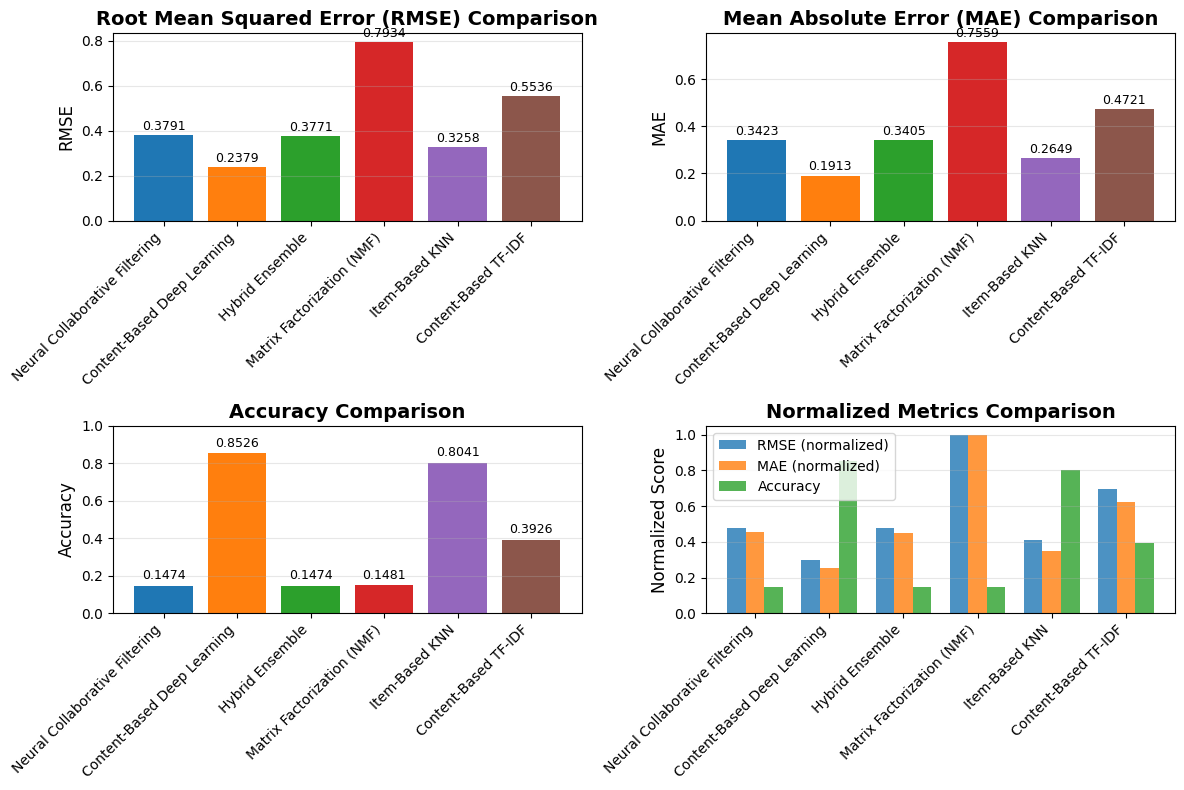

Model comparison graphs saved!


In [27]:
# --------------------------
# VISUALIZATION: MODEL ACCURACY COMPARISON
# --------------------------

plt.figure(figsize=(12, 8))

# Plot 1: RMSE Comparison
plt.subplot(2, 2, 1)
plt.bar(results_df['Model'], results_df['RMSE'], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b'])
plt.title('Root Mean Squared Error (RMSE) Comparison', fontsize=14, fontweight='bold')
plt.ylabel('RMSE', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
for i, v in enumerate(results_df['RMSE']):
    plt.text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontsize=9)

# Plot 2: MAE Comparison
plt.subplot(2, 2, 2)
plt.bar(results_df['Model'], results_df['MAE'], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b'])
plt.title('Mean Absolute Error (MAE) Comparison', fontsize=14, fontweight='bold')
plt.ylabel('MAE', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
for i, v in enumerate(results_df['MAE']):
    plt.text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontsize=9)

# Plot 3: Accuracy Comparison
plt.subplot(2, 2, 3)
plt.bar(results_df['Model'], results_df['Accuracy'], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b'])
plt.title('Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.ylim([0, 1])
for i, v in enumerate(results_df['Accuracy']):
    plt.text(i, v + 0.02, f'{v:.4f}', ha='center', va='bottom', fontsize=9)

# Plot 4: Combined Metrics
plt.subplot(2, 2, 4)
x = np.arange(len(results_df['Model']))
width = 0.25
plt.bar(x - width, results_df['RMSE'] / results_df['RMSE'].max(), width, label='RMSE (normalized)', alpha=0.8)
plt.bar(x, results_df['MAE'] / results_df['MAE'].max(), width, label='MAE (normalized)', alpha=0.8)
plt.bar(x + width, results_df['Accuracy'], width, label='Accuracy', alpha=0.8)
plt.title('Normalized Metrics Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Normalized Score', fontsize=12)
plt.xticks(x, results_df['Model'], rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Model comparison graphs saved!")


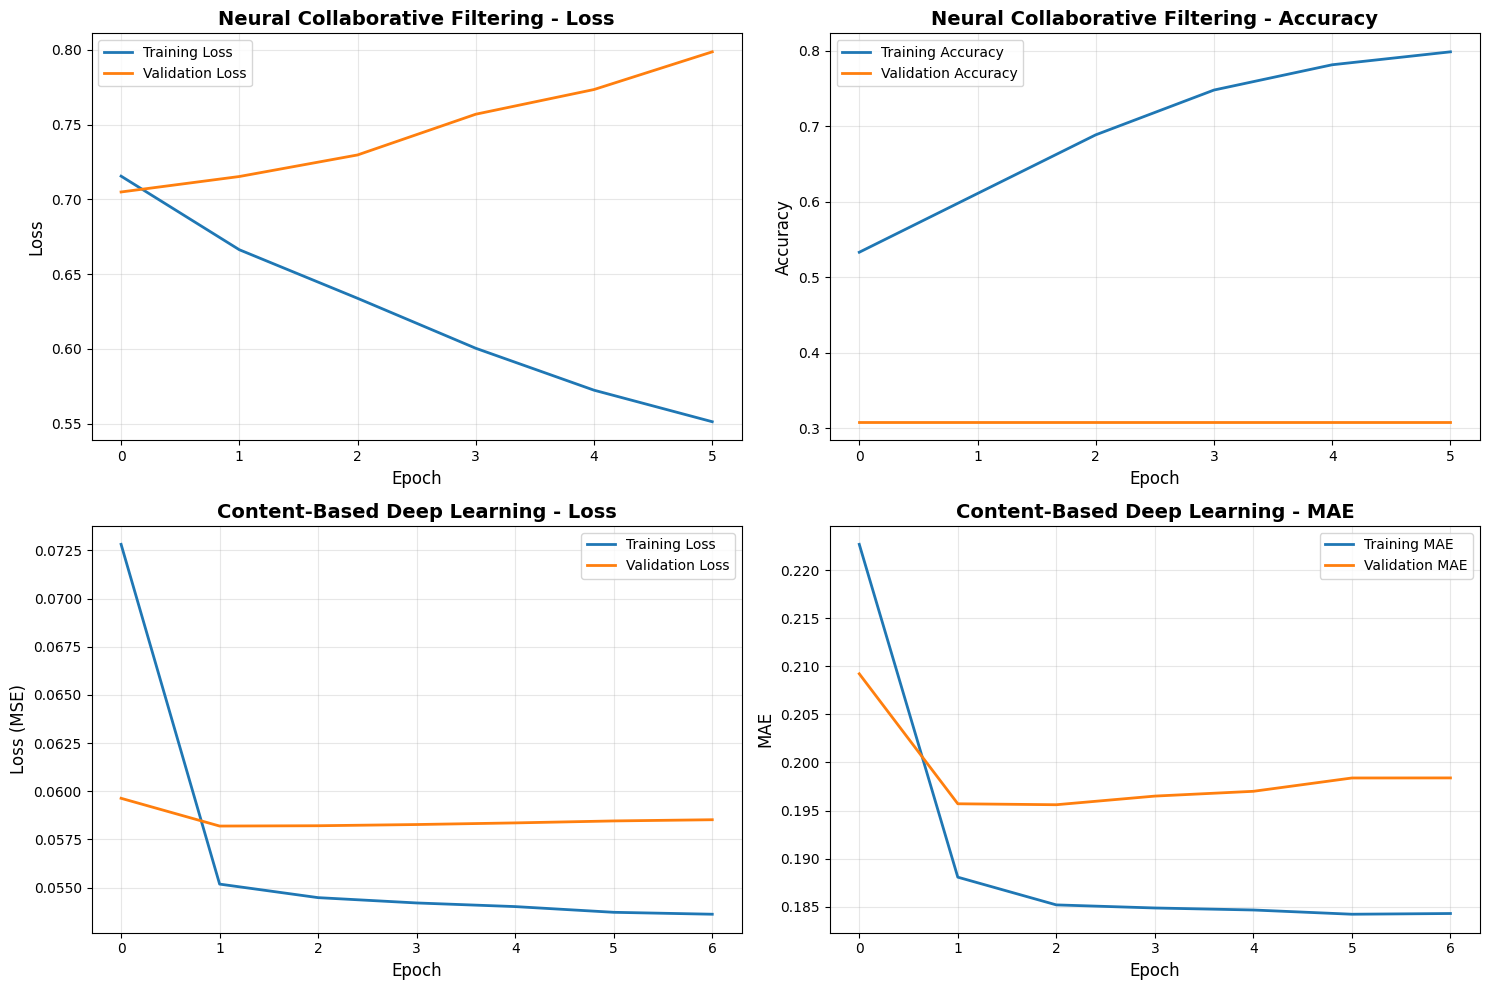

Training history graphs saved!


In [28]:
# --------------------------
# VISUALIZATION: TRAINING HISTORY
# --------------------------

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# NCF Training History
axes[0, 0].plot(ncf_history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(ncf_history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Neural Collaborative Filtering - Loss', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(ncf_history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0, 1].plot(ncf_history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0, 1].set_title('Neural Collaborative Filtering - Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy', fontsize=12)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Content-Based Training History
axes[1, 0].plot(content_history.history['loss'], label='Training Loss', linewidth=2)
axes[1, 0].plot(content_history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[1, 0].set_title('Content-Based Deep Learning - Loss', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('Loss (MSE)', fontsize=12)
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(content_history.history['mae'], label='Training MAE', linewidth=2)
axes[1, 1].plot(content_history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1, 1].set_title('Content-Based Deep Learning - MAE', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('MAE', fontsize=12)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("Training history graphs saved!")


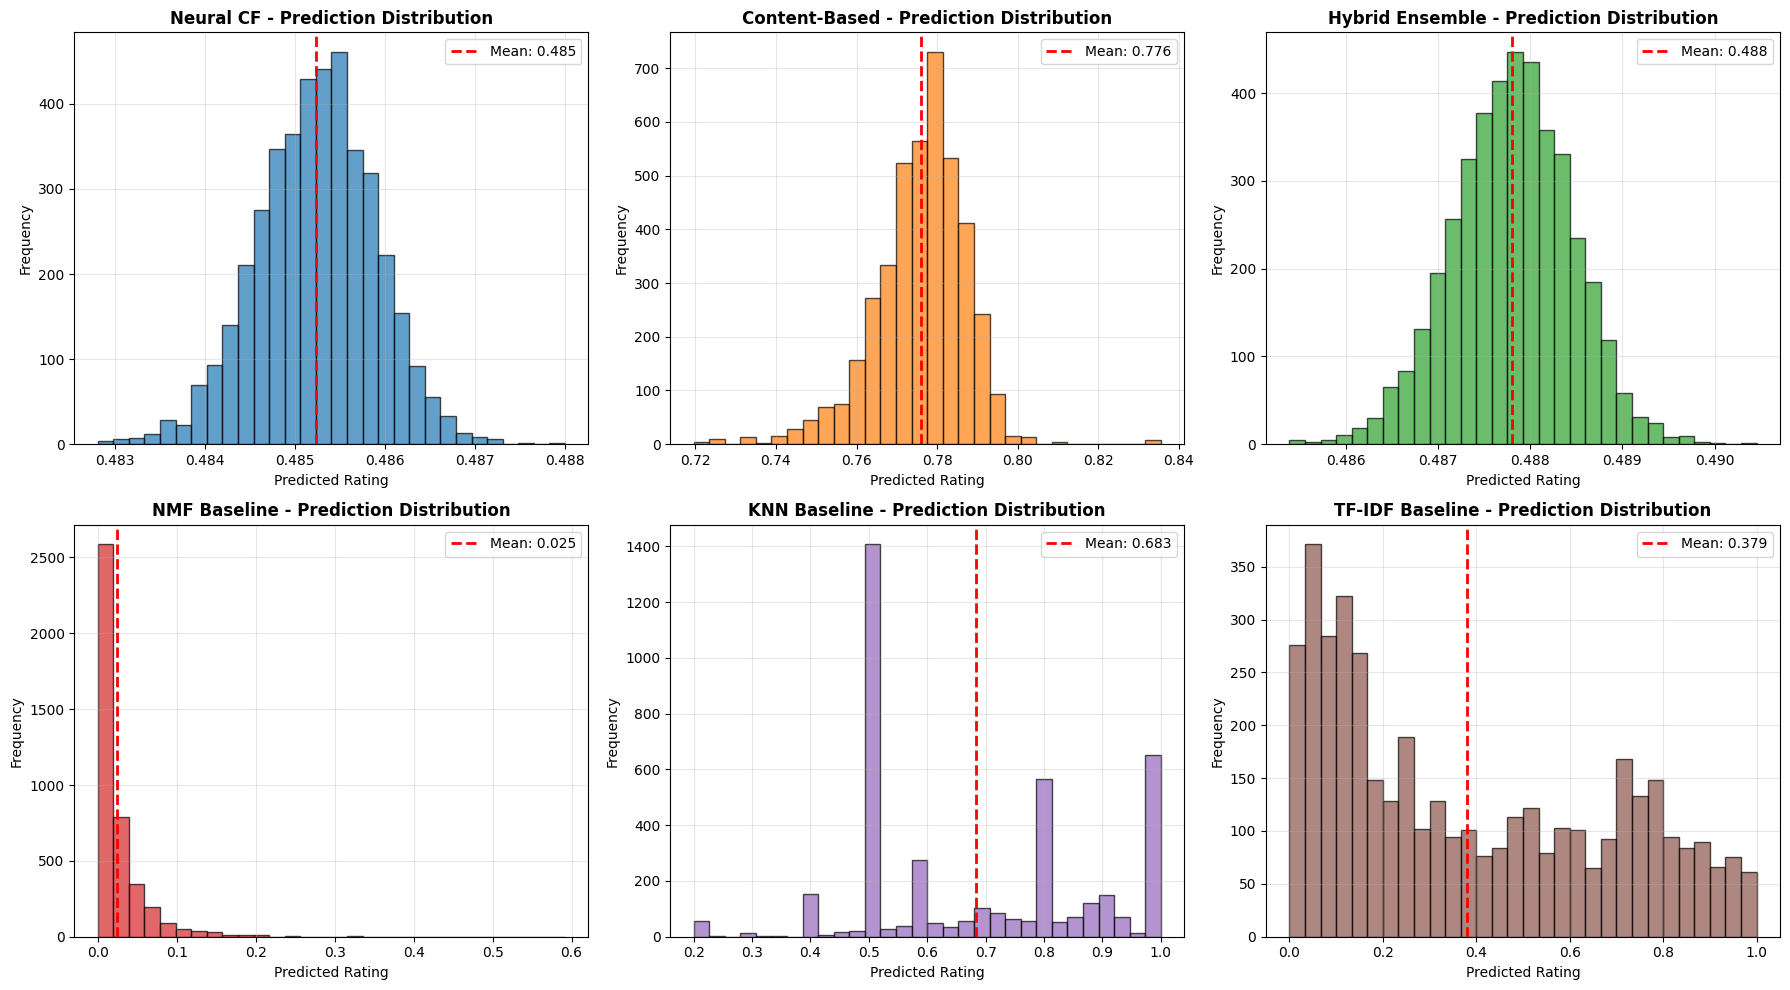

Prediction distribution graphs saved!


In [29]:
# --------------------------
# VISUALIZATION: PREDICTION DISTRIBUTION
# --------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

models_preds = {
    'Neural CF': test_ncf_preds,
    'Content-Based': test_content_preds,
    'Hybrid Ensemble': test_ensemble_preds,
    'NMF Baseline': test_nmf_preds,
    'KNN Baseline': test_knn_preds,
    'TF-IDF Baseline': test_tfidf_preds
}

for idx, (model_name, preds) in enumerate(models_preds.items()):
    row = idx // 3
    col = idx % 3
    
    axes[row, col].hist(preds, bins=30, alpha=0.7, edgecolor='black', color=plt.cm.tab10(idx))
    axes[row, col].axvline(np.mean(preds), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(preds):.3f}')
    axes[row, col].set_title(f'{model_name} - Prediction Distribution', fontsize=12, fontweight='bold')
    axes[row, col].set_xlabel('Predicted Rating', fontsize=10)
    axes[row, col].set_ylabel('Frequency', fontsize=10)
    axes[row, col].legend()
    axes[row, col].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('prediction_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print("Prediction distribution graphs saved!")


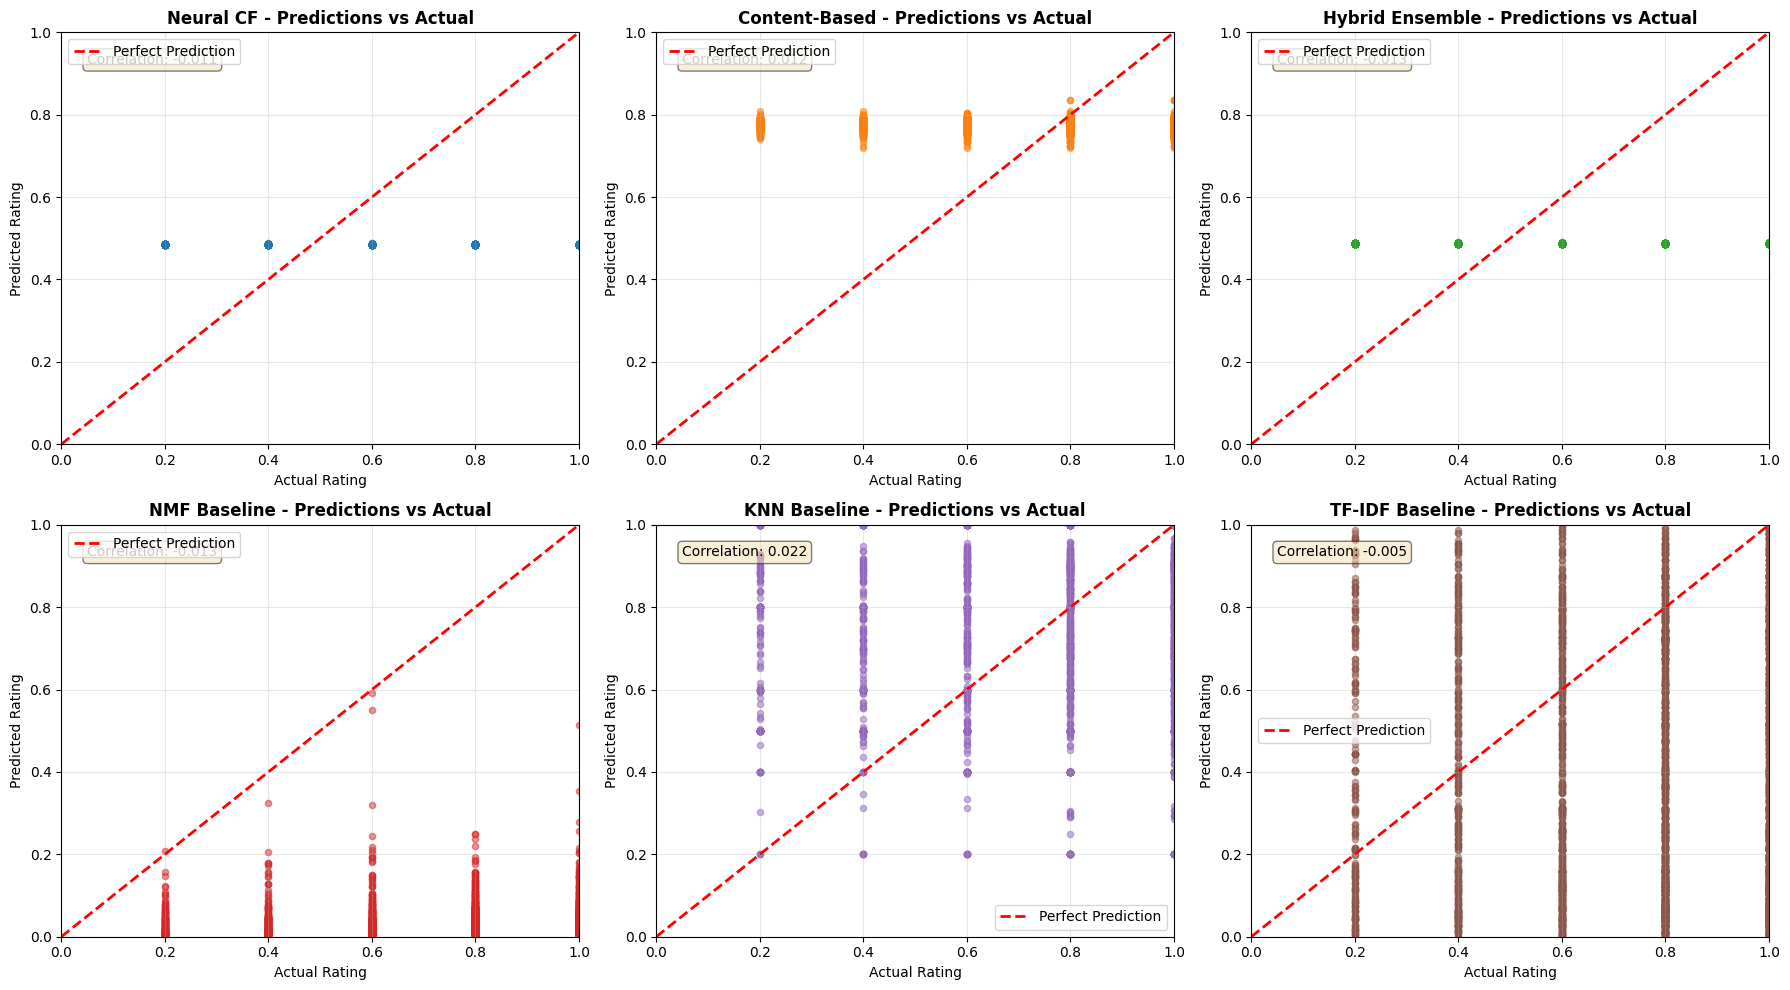

Prediction vs actual graphs saved!


In [30]:
# --------------------------
# VISUALIZATION: PREDICTION VS ACTUAL (SCATTER PLOTS)
# --------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, (model_name, preds) in enumerate(models_preds.items()):
    row = idx // 3
    col = idx % 3
    
    axes[row, col].scatter(test_labels, preds, alpha=0.5, s=20, color=plt.cm.tab10(idx))
    axes[row, col].plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect Prediction')
    axes[row, col].set_title(f'{model_name} - Predictions vs Actual', fontsize=12, fontweight='bold')
    axes[row, col].set_xlabel('Actual Rating', fontsize=10)
    axes[row, col].set_ylabel('Predicted Rating', fontsize=10)
    axes[row, col].set_xlim([0, 1])
    axes[row, col].set_ylim([0, 1])
    axes[row, col].legend()
    axes[row, col].grid(alpha=0.3)
    
    # Add correlation coefficient
    corr = np.corrcoef(test_labels, preds)[0, 1]
    axes[row, col].text(0.05, 0.95, f'Correlation: {corr:.3f}', 
                        transform=axes[row, col].transAxes, 
                        fontsize=10, verticalalignment='top',
                        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('predictions_vs_actual.png', dpi=300, bbox_inches='tight')
plt.show()

print("Prediction vs actual graphs saved!")


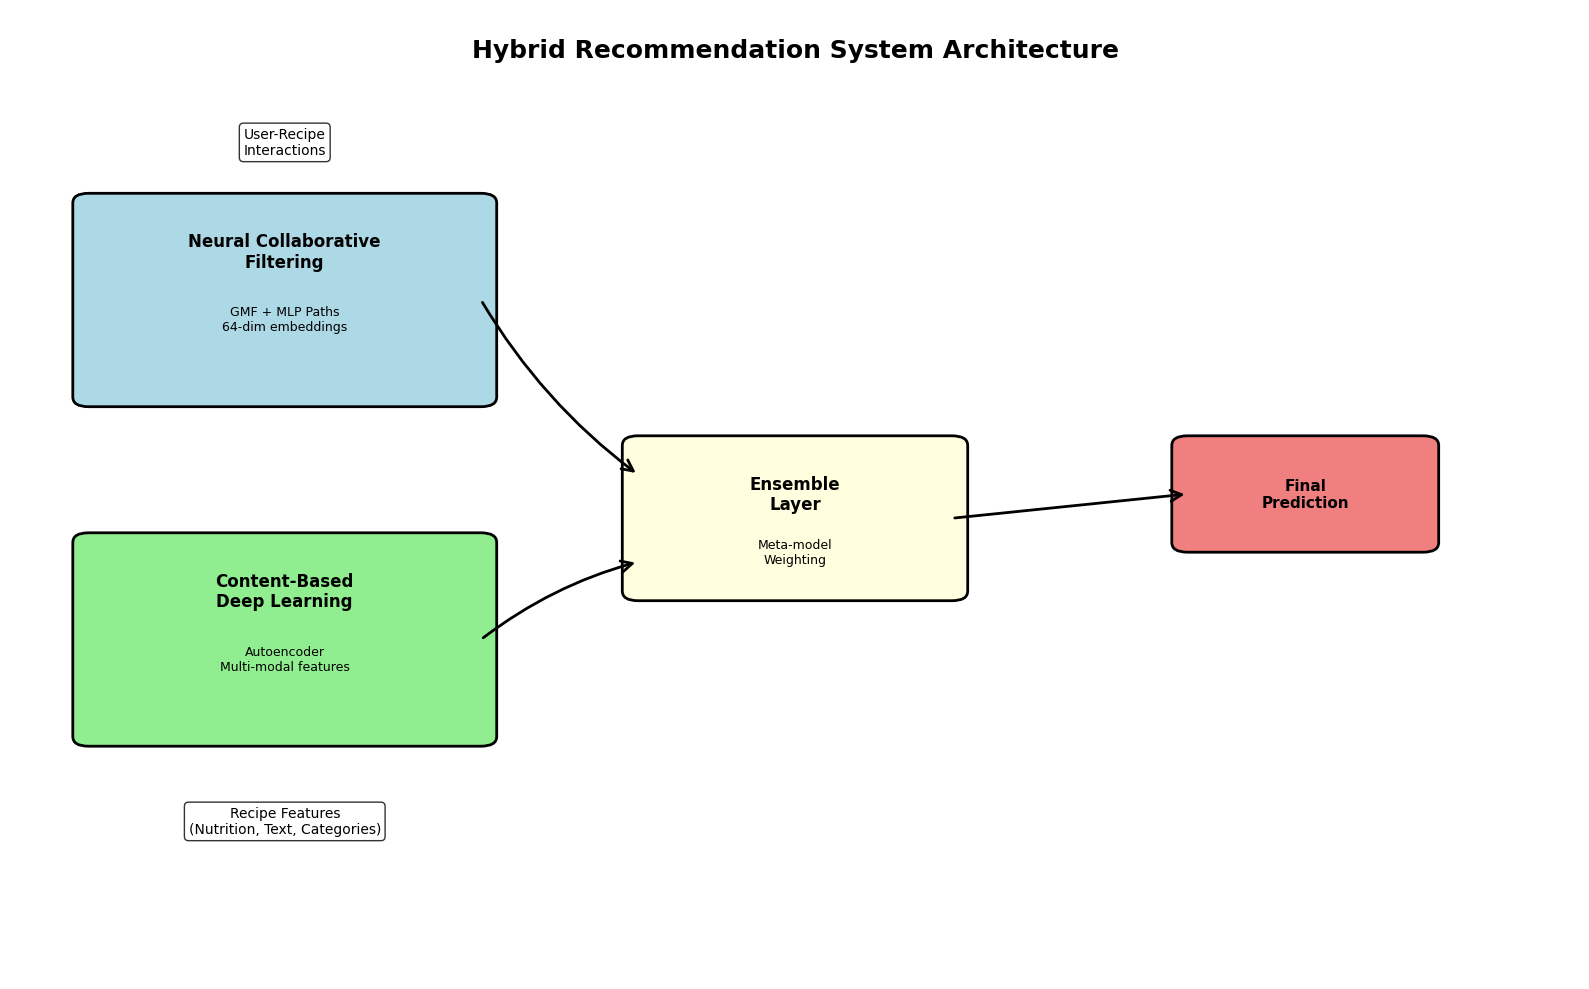

Architecture diagram saved!


In [31]:
# --------------------------
# VISUALIZATION: ARCHITECTURE DIAGRAM (SIMPLIFIED)
# --------------------------

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patches as mpatches

fig, ax = plt.subplots(1, 1, figsize=(16, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Title
ax.text(5, 9.5, 'Hybrid Recommendation System Architecture', 
        ha='center', fontsize=18, fontweight='bold')

# Neural Collaborative Filtering Component
ncf_box = FancyBboxPatch((0.5, 6), 2.5, 2, boxstyle="round,pad=0.1", 
                         facecolor='lightblue', edgecolor='black', linewidth=2)
ax.add_patch(ncf_box)
ax.text(1.75, 7.5, 'Neural Collaborative\nFiltering', ha='center', va='center', 
        fontsize=12, fontweight='bold')
ax.text(1.75, 6.8, 'GMF + MLP Paths\n64-dim embeddings', ha='center', va='center', 
        fontsize=9)

# Content-Based Component
content_box = FancyBboxPatch((0.5, 2.5), 2.5, 2, boxstyle="round,pad=0.1", 
                             facecolor='lightgreen', edgecolor='black', linewidth=2)
ax.add_patch(content_box)
ax.text(1.75, 4, 'Content-Based\nDeep Learning', ha='center', va='center', 
        fontsize=12, fontweight='bold')
ax.text(1.75, 3.3, 'Autoencoder\nMulti-modal features', ha='center', va='center', 
        fontsize=9)

# Ensemble Layer
ensemble_box = FancyBboxPatch((4, 4), 2, 1.5, boxstyle="round,pad=0.1", 
                              facecolor='lightyellow', edgecolor='black', linewidth=2)
ax.add_patch(ensemble_box)
ax.text(5, 5, 'Ensemble\nLayer', ha='center', va='center', 
        fontsize=12, fontweight='bold')
ax.text(5, 4.4, 'Meta-model\nWeighting', ha='center', va='center', 
        fontsize=9)

# Final Prediction
pred_box = FancyBboxPatch((7.5, 4.5), 1.5, 1, boxstyle="round,pad=0.1", 
                          facecolor='lightcoral', edgecolor='black', linewidth=2)
ax.add_patch(pred_box)
ax.text(8.25, 5, 'Final\nPrediction', ha='center', va='center', 
        fontsize=11, fontweight='bold')

# Arrows
arrow1 = FancyArrowPatch((3, 7), (4, 5.2), connectionstyle="arc3,rad=0.1",
                         arrowstyle='->', mutation_scale=20, linewidth=2, color='black')
ax.add_patch(arrow1)

arrow2 = FancyArrowPatch((3, 3.5), (4, 4.3), connectionstyle="arc3,rad=-0.1",
                         arrowstyle='->', mutation_scale=20, linewidth=2, color='black')
ax.add_patch(arrow2)

arrow3 = FancyArrowPatch((6, 4.75), (7.5, 5), connectionstyle="arc3,rad=0",
                         arrowstyle='->', mutation_scale=20, linewidth=2, color='black')
ax.add_patch(arrow3)

# Input labels
ax.text(1.75, 8.5, 'User-Recipe\nInteractions', ha='center', fontsize=10, 
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.text(1.75, 1.5, 'Recipe Features\n(Nutrition, Text, Categories)', ha='center', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('architecture_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print("Architecture diagram saved!")


In [32]:
# --------------------------
# GENERATE RECOMMENDATIONS FOR USER USING HYBRID MODEL
# --------------------------

# Create a representative user ID for the meal plan (using first user from interactions)
representative_user_id = interactions_df['user_id'].iloc[0]
representative_user_idx = user_to_idx[representative_user_id]

# Get predictions for all filtered recipes using the hybrid ensemble model
print("Generating recommendations for all filtered recipes using Hybrid Ensemble Model...")

# Prepare recipe indices for all filtered recipes
all_recipe_indices = np.arange(len(filtered_diet))

# NCF predictions (need user_idx for all recipes)
all_user_indices_ncf = np.full(len(filtered_diet), representative_user_idx)
all_recipe_indices_ncf = np.array([recipe_to_idx.get(idx, 0) for idx in all_recipe_indices])

# Get NCF predictions
all_ncf_preds = ncf_model.predict([all_user_indices_ncf, all_recipe_indices_ncf], verbose=0).flatten()

# Content-based predictions
all_nutritional = nutritional_features_scaled[all_recipe_indices]
all_text = text_padded[all_recipe_indices]
all_categorical = categorical_features[all_recipe_indices]

# User preferences for meal planning
user_pref_meal = np.tile([target_calories/2000, target_protein/200, target_fat/100, target_carbs/300], 
                         (len(filtered_diet), 1))
user_pref_meal = nutritional_scaler.transform(user_pref_meal)

# Get content-based predictions
all_content_preds = content_model.predict(
    [all_nutritional, all_text, all_categorical, user_pref_meal], verbose=0
).flatten()

# Ensemble predictions
all_recipe_ids = all_recipe_indices
all_user_ids_meal = np.full(len(filtered_diet), representative_user_id)

all_features_meal = []
for user_id, recipe_id in zip(all_user_ids_meal, all_recipe_ids):
    features = ensemble.extract_confidence_features(
        user_id, recipe_id, interactions_df,
        user_interaction_counts, recipe_interaction_counts
    )
    all_features_meal.append(features)

all_features_meal = np.array(all_features_meal)
collab_weights_meal, content_weights_meal = ensemble.predict_weights(
    all_features_meal, all_ncf_preds, all_content_preds
)

# Get ensemble predictions
all_ensemble_preds = ensemble.ensemble_predict(
    all_ncf_preds, all_content_preds, collab_weights_meal, content_weights_meal
)

# Add predictions to filtered_diet dataframe
filtered_diet['Hybrid_Score'] = all_ensemble_preds
filtered_diet['NCF_Score'] = all_ncf_preds
filtered_diet['Content_Score'] = all_content_preds

# Sort by hybrid ensemble score
filtered_diet_sorted = filtered_diet.sort_values('Hybrid_Score', ascending=False).reset_index(drop=True)

print(f"Generated recommendations for {len(filtered_diet_sorted)} recipes")
print(f"Top 5 recommended recipes:")
print(filtered_diet_sorted[['Name', 'Calories', 'ProteinContent', 'FatContent', 
                            'CarbohydrateContent', 'Hybrid_Score']].head())


Generating recommendations for all filtered recipes using Hybrid Ensemble Model...
Generated recommendations for 716 recipes
Top 5 recommended recipes:
                                       Name  Calories  ProteinContent  \
0                      sweet potato patties      62.3             2.4   
1            kosher vegetarian tomato curry       0.0             0.0   
2  baked beans, cheddar and pickle sandwich     468.2            22.5   
3                        wild rice stuffing     249.2             8.2   
4            roasted red pepper hummus soup     228.7             8.4   

   FatContent  CarbohydrateContent  Hybrid_Score  
0         1.1                 10.7      0.489778  
1         0.0                  0.0      0.489700  
2        16.8                 61.0      0.489606  
3         4.6                 44.1      0.489427  
4         8.8                 29.6      0.489399  


In [33]:
# --------------------------
# 7-DAY MEAL PLAN GENERATOR USING HYBRID MODEL
# --------------------------

def generate_7day_plan_hybrid(filtered_diet_sorted, target_calories_per_day, 
                               target_protein_per_day, target_fat_per_day, target_carbs_per_day,
                               caloric_tolerance=0.2, macro_tolerance=0.1):
    """
    Generate 7-day meal plan using hybrid model recommendations
    with nutritional constraints
    """
    days = []
    
    for day in range(7):
        day_plan = []
        remaining_calories = target_calories_per_day
        remaining_protein = target_protein_per_day
        remaining_fat = target_fat_per_day
        remaining_carbs = target_carbs_per_day
        
        # Shuffle recipes for variety while maintaining quality (top 200 by score)
        top_recipes = filtered_diet_sorted.head(200)
        recipes_shuffled = top_recipes.sample(frac=1, random_state=day).reset_index(drop=True)
        
        for _, recipe in recipes_shuffled.iterrows():
            recipe_calories = recipe['Calories']
            recipe_protein = recipe['ProteinContent']
            recipe_fat = recipe['FatContent']
            recipe_carbs = recipe['CarbohydrateContent']
            
            # Check if recipe fits within nutritional constraints
            caloric_ok = recipe_calories <= remaining_calories * (1 + caloric_tolerance)
            protein_ok = recipe_protein <= remaining_protein * (1 + macro_tolerance) or remaining_protein <= 0
            fat_ok = recipe_fat <= remaining_fat * (1 + macro_tolerance) or remaining_fat <= 0
            carbs_ok = recipe_carbs <= remaining_carbs * (1 + macro_tolerance) or remaining_carbs <= 0
            
            if caloric_ok and protein_ok and fat_ok and carbs_ok:
                day_plan.append(recipe)
                remaining_calories -= recipe_calories
                remaining_protein -= recipe_protein
                remaining_fat -= recipe_fat
                remaining_carbs -= recipe_carbs
                
                # Stop if we've reached daily targets (with tolerance)
                if remaining_calories <= target_calories_per_day * caloric_tolerance:
                    break
        
        days.append(day_plan)
    
    return days

# Generate 7-day meal plan
meal_plan_7days = generate_7day_plan_hybrid(
    filtered_diet_sorted, 
    target_calories,
    target_protein,
    target_fat,
    target_carbs
)

print("7-day personalized meal plan generated using Hybrid Ensemble Model!")


7-day personalized meal plan generated using Hybrid Ensemble Model!


In [34]:
# --------------------------
# DISPLAY MEAL PLAN WITH HYBRID MODEL SCORES
# --------------------------

for i, day in enumerate(meal_plan_7days, 1):
    print(f"\n{'='*60}")
    print(f"🍽️  DAY {i} MEAL PLAN (Generated by Hybrid Ensemble Model)")
    print(f"{'='*60}")

    # Compute totals
    total_calories = sum([r['Calories'] for r in day])
    total_protein = sum([r['ProteinContent'] for r in day])
    total_fat = sum([r['FatContent'] for r in day])
    total_carbs = sum([r['CarbohydrateContent'] for r in day])
    
    # Calculate target percentages
    cal_diff = abs(total_calories - target_calories) / target_calories * 100
    protein_diff = abs(total_protein - target_protein) / target_protein * 100 if target_protein > 0 else 0
    fat_diff = abs(total_fat - target_fat) / target_fat * 100 if target_fat > 0 else 0
    carbs_diff = abs(total_carbs - target_carbs) / target_carbs * 100 if target_carbs > 0 else 0

    print(f"🔹 Total Calories: {total_calories:.0f} kcal (Target: {target_calories:.0f}, Diff: {cal_diff:.1f}%)")
    print(f"🔹 Protein: {total_protein:.1f} g (Target: {target_protein:.1f}, Diff: {protein_diff:.1f}%)")
    print(f"🔹 Fat: {total_fat:.1f} g (Target: {target_fat:.1f}, Diff: {fat_diff:.1f}%)")
    print(f"🔹 Carbs: {total_carbs:.1f} g (Target: {target_carbs:.1f}, Diff: {carbs_diff:.1f}%)")
    print(f"{'-'*60}\n")

    # Print each meal with model scores
    for j, meal in enumerate(day, 1):
        print(f"🥗 Meal {j}: {meal['Name'].title()}")
        print(f"   📊 Hybrid Score: {meal['Hybrid_Score']:.4f} | NCF: {meal['NCF_Score']:.4f} | Content: {meal['Content_Score']:.4f}")
        print(f"   💪 {meal['Calories']:.0f} kcal | Protein: {meal['ProteinContent']:.1f} g | Fat: {meal['FatContent']:.1f} g | Carbs: {meal['CarbohydrateContent']:.1f} g")
        print(f"   📖 Instructions: {meal['RecipeInstructions'][:150]}..." if len(meal['RecipeInstructions']) > 150 else f"   📖 Instructions: {meal['RecipeInstructions']}")
        print(f"{'-'*60}")



🍽️  DAY 1 MEAL PLAN (Generated by Hybrid Ensemble Model)
🔹 Total Calories: 1421 kcal (Target: 1587, Diff: 10.5%)
🔹 Protein: 38.9 g (Target: 119.0, Diff: 67.3%)
🔹 Fat: 40.7 g (Target: 52.9, Diff: 23.1%)
🔹 Carbs: 226.2 g (Target: 158.7, Diff: 42.5%)
------------------------------------------------------------

🥗 Meal 1: Fresh Corn Risotto
   📊 Hybrid Score: 0.4891 | NCF: 0.4866 | Content: 0.7762
   💪 332 kcal | Protein: 12.0 g | Fat: 11.1 g | Carbs: 47.5 g
   📖 Instructions: Reserve 12 the quantity of kernels about 1 and 12 cups and puree the rest in a blender with some of the stockbroth Strain through a sieve and add this...
------------------------------------------------------------
🥗 Meal 2: Oven Baked Vegetarian Rice
   📊 Hybrid Score: 0.4884 | NCF: 0.4853 | Content: 0.7412
   💪 334 kcal | Protein: 6.6 g | Fat: 11.2 g | Carbs: 51.9 g
   📖 Instructions: Preheat oven at 350 degrees chop veggies Mix all ingredients in a 2 quart casserole dish Bake for 1 hour For Vegetarian use Vegetab